# Predicting Student Dropout and Academic Success Using Data Science
 Load libraries and data

In [25]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import kruskal
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
DATA_PATH = "Studentdata.csv"  # Keep the CSV in the same folder as this notebook.
df = pd.read_csv(DATA_PATH, sep=";")
print("First five rows:")
display(df.head())
print("\nDataset shape:", df.shape)
print("\nData types:")
display(df.dtypes.astype(str).value_counts().rename_axis("dtype").to_frame("column_count"))
print("\nColumn names:")
print(df.columns.tolist())

First five rows:


,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate



Dataset shape: (4424, 37)

Data types:


,column_count
dtype,
int64,29
float64,7
object,1



Column names:
['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Previous qualification (grade)', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation", 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Curricular units 1st sem (credited)', 'Curricular units 1st sem (enrolled)', 'Curricular units 1st sem (evaluations)', 'Curricular units 1st sem (approved)', 'Curricular units 1st sem (grade)', 'Curricular units 1st sem (without evaluations)', 'Curricular units 2nd sem (credited)', 'Curricular units 2nd sem (enrolled)', 'Curricular units 2nd sem (evaluations)', 'Curricular units 2nd sem (approved)', 'Curricular units 2nd sem (grade)', 'Curricular units 2nd sem (without evaluations)', 'Unemployment rate', 'Inflation rate', 'GDP', 'Targe

**Observation:** the file uses semicolons as delimiters. The target column is `Target`, with three classes: Dropout, Enrolled and Graduate. Numeric storage does not always mean a variable is truly continuous: many columns are coded categories (for example, application mode, course, nationality and occupations).

## 4. Data quality checks and variable types

The data dictionary matters: binary flags are usually 0/1, coded categories are integer labels, and continuous measurements include age, grades and macroeconomic rates. We check missing values, duplicates, impossible negative counts and basic value ranges. Domain-specific codes should be checked against the official data dictionary before being treated as errors.

In [26]:
target_col = "Target"
print("Target counts:")
display(df[target_col].value_counts().to_frame("count"))
print("\nTarget percentages:")
display((df[target_col].value_counts(normalize=True).mul(100).round(2)).to_frame("percent"))

missing = df.isna().sum().sort_values(ascending=False)
print("\nColumns with missing values:")
display(missing[missing > 0].to_frame("missing_count") if (missing > 0).any() else pd.DataFrame({"message":["No missing values detected."]}))

print("\nExact duplicate rows:", int(df.duplicated().sum()))
print("Unique target labels:", sorted(df[target_col].dropna().unique().tolist()))

binary_candidates = [c for c in df.columns if df[c].dropna().nunique() == 2 and c != target_col]
coded_categorical = [
    "Marital status", "Application mode", "Application order", "Course",
    "Daytime/evening attendance\t", "Previous qualification", "Nacionality",
    "Mother's qualification", "Father's qualification", "Mother's occupation",
    "Father's occupation"
]
print("\nBinary-like columns (two distinct observed values):", binary_candidates)
print("\nExamples of coded categorical columns:", [c for c in coded_categorical if c in df.columns])

# Basic unusual-value checks. These are flags for review, not automatic deletions.
count_cols = [c for c in df.columns if "Curricular units" in c and any(k in c for k in ["credited","enrolled","evaluations","approved","without evaluations"])]
negative_counts = {c: int((df[c] < 0).sum()) for c in count_cols if pd.api.types.is_numeric_dtype(df[c])}
print("\nNegative curricular-unit counts by column:", negative_counts)
print("Age range:", (df["Age at enrollment"].min(), df["Age at enrollment"].max()))
print("Admission grade range:", (df["Admission grade"].min(), df["Admission grade"].max()))

Target counts:


,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794



Target percentages:


,percent
Target,
Graduate,49.93
Dropout,32.12
Enrolled,17.95



Columns with missing values:


,message
0,No missing values detected.



Exact duplicate rows: 0
Unique target labels: ['Dropout', 'Enrolled', 'Graduate']

Binary-like columns (two distinct observed values): ['Daytime/evening attendance\t', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International']

Examples of coded categorical columns: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]

Negative curricular-unit counts by column: {'Curricular units 1st sem (credited)': 0, 'Curricular units 1st sem (enrolled)': 0, 'Curricular units 1st sem (evaluations)': 0, 'Curricular units 1st sem (approved)': 0, 'Curricular units 1st sem (without evaluations)': 0, 'Curricular units 2nd sem (credited)': 0, 'Curricular units 2nd sem (enrolled)': 0, 'Curricular units 2nd sem (evaluations)': 0, 'Curricular units 2nd se

**Preprocessing decisions:** preserve valid rows; do not delete unusual values without checking their meaning. The pipeline below imputes missing numerical values with the median, scales numeric predictors, imputes categorical values with the most frequent category and one-hot encodes them. This avoids treating arbitrary category codes as ordered numeric quantities.

## 5. Exploratory data analysis and statistics

,Count,Percent
Target,,
Dropout,1421,32.12
Enrolled,794,17.95
Graduate,2209,49.93


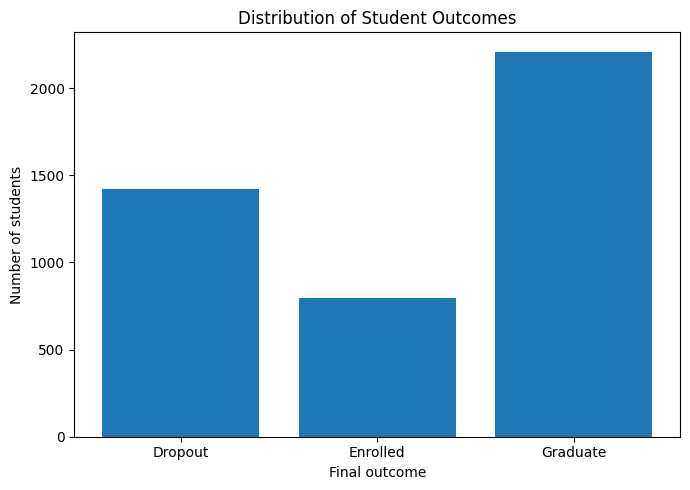

Interpretation: the target classes are imbalanced. Accuracy alone may hide weak performance on the smaller Enrolled class.


In [27]:
class_counts = df[target_col].value_counts().reindex(["Dropout", "Enrolled", "Graduate"])
class_percent = df[target_col].value_counts(normalize=True).reindex(["Dropout", "Enrolled", "Graduate"]) * 100
class_table = pd.DataFrame({"Count": class_counts, "Percent": class_percent.round(2)})
display(class_table)

plt.figure(figsize=(7, 5))
plt.bar(class_table.index, class_table["Count"])
plt.title("Distribution of Student Outcomes")
plt.xlabel("Final outcome")
plt.ylabel("Number of students")
plt.tight_layout()
plt.show()

print("Interpretation: the target classes are imbalanced. Accuracy alone may hide weak performance on the smaller Enrolled class.")

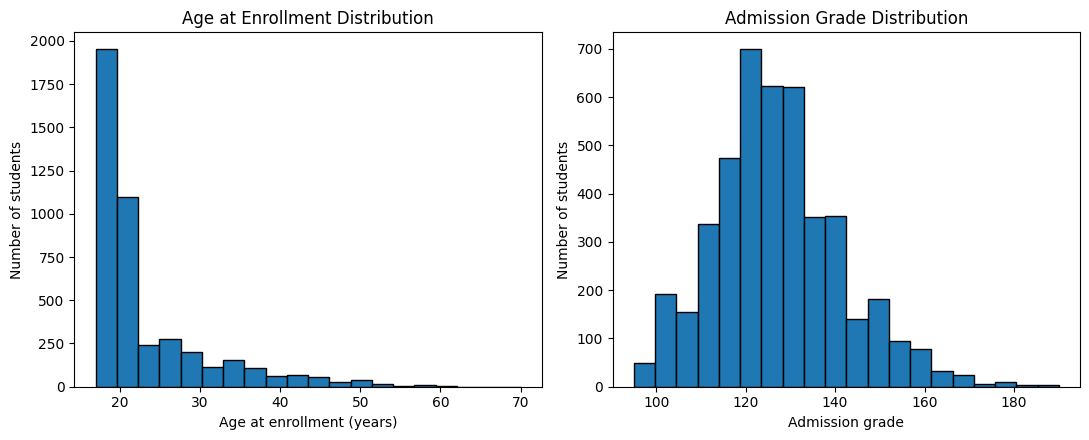

Descriptive statistics:


,Age at enrollment,Admission grade,Curricular units 1st sem (grade),Curricular units 2nd sem (grade)
count,4424.00,4424.00,4424.00,4424.00
mean,23.27,126.98,10.64,10.23
std,7.59,14.48,4.84,5.21
min,17.00,95.00,0.00,0.00
25%,19.00,117.90,11.00,10.75
50%,20.00,126.10,12.29,12.20
75%,25.00,134.80,13.40,13.33
max,70.00,190.00,18.88,18.57


In [28]:
# Histograms of selected numerical attributes
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].hist(df["Age at enrollment"].dropna(), bins=20, edgecolor="black")
axes[0].set_title("Age at Enrollment Distribution")
axes[0].set_xlabel("Age at enrollment (years)")
axes[0].set_ylabel("Number of students")

axes[1].hist(df["Admission grade"].dropna(), bins=20, edgecolor="black")
axes[1].set_title("Admission Grade Distribution")
axes[1].set_xlabel("Admission grade")
axes[1].set_ylabel("Number of students")
plt.tight_layout()
plt.show()

print("Descriptive statistics:")
display(df[["Age at enrollment", "Admission grade",
            "Curricular units 1st sem (grade)",
            "Curricular units 2nd sem (grade)"]].describe().round(2))

<Figure size 800x500 with 0 Axes>

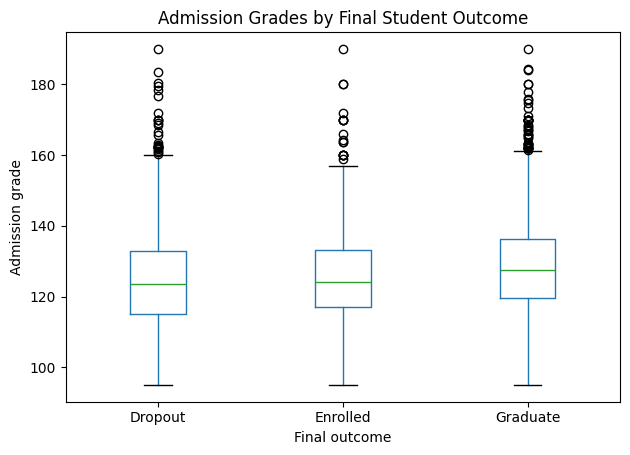

,count,mean,median,std
Target,,,,
Dropout,1421,124.96,123.6,15.13
Enrolled,794,125.53,124.1,13.79
Graduate,2209,128.79,127.4,14.07


Interpretation: compare medians, spread and overlap. Differences are associations and do not prove admission grade causes an outcome.


In [29]:
# Admission grade across final outcomes
outcome_order = ["Dropout", "Enrolled", "Graduate"]
plt.figure(figsize=(8, 5))
df.boxplot(column="Admission grade", by=target_col, grid=False)
plt.title("Admission Grades by Final Student Outcome")
plt.suptitle("")
plt.xlabel("Final outcome")
plt.ylabel("Admission grade")
plt.tight_layout()
plt.show()

admission_summary = df.groupby(target_col)["Admission grade"].agg(["count","mean","median","std"]).reindex(outcome_order).round(2)
display(admission_summary)
print("Interpretation: compare medians, spread and overlap. Differences are associations and do not prove admission grade causes an outcome.")

<Figure size 800x500 with 0 Axes>

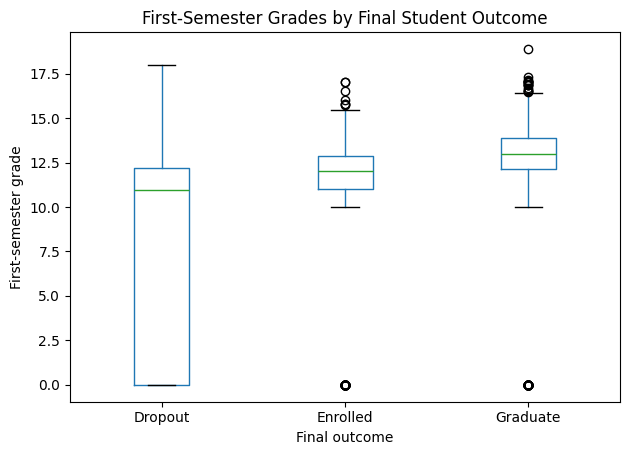

,count,mean,median,std
Target,,,,
Dropout,1421,7.26,10.93,6.03
Enrolled,794,11.13,12.00,3.68
Graduate,2209,12.64,13.00,2.70


Target,Dropout,Enrolled,Graduate
Age at enrollment,,,
20 or younger,21.2,18.5,60.3
21–25,35.6,22.0,42.4
26–30,59.8,14.9,25.3
31–40,55.1,13.3,31.6
Over 40,50.7,11.6,37.8


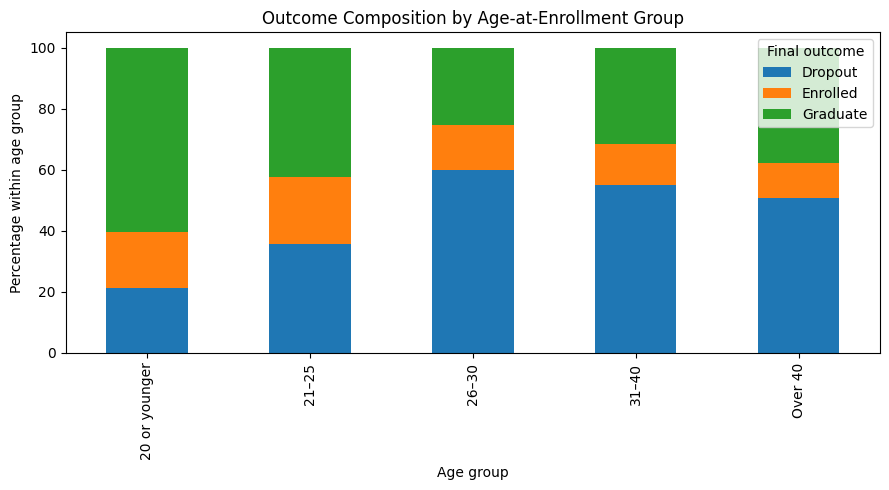

Interpretation: semester grades may separate outcomes strongly because they occur during the course. They are useful for monitoring after semester one, but would leak future information in a model intended to predict at enrollment.


In [30]:
# First-semester academic performance by final outcome
plt.figure(figsize=(8, 5))
df.boxplot(column="Curricular units 1st sem (grade)", by=target_col, grid=False)
plt.title("First-Semester Grades by Final Student Outcome")
plt.suptitle("")
plt.xlabel("Final outcome")
plt.ylabel("First-semester grade")
plt.tight_layout()
plt.show()

sem1_summary = df.groupby(target_col)["Curricular units 1st sem (grade)"].agg(["count","mean","median","std"]).reindex(outcome_order).round(2)
display(sem1_summary)

# Age and outcome distribution
age_bins = pd.cut(df["Age at enrollment"], bins=[-np.inf,20,25,30,40,np.inf],
                  labels=["20 or younger","21–25","26–30","31–40","Over 40"])
age_outcome = pd.crosstab(age_bins, df[target_col], normalize="index").reindex(columns=outcome_order) * 100
display(age_outcome.round(1))
age_outcome.plot(kind="bar", stacked=True, figsize=(9,5))
plt.title("Outcome Composition by Age-at-Enrollment Group")
plt.xlabel("Age group")
plt.ylabel("Percentage within age group")
plt.legend(title="Final outcome")
plt.tight_layout()
plt.show()

print("Interpretation: semester grades may separate outcomes strongly because they occur during the course. They are useful for monitoring after semester one, but would leak future information in a model intended to predict at enrollment.")

## 6. Hypothesis test: first-semester grades across outcomes

**Null hypothesis (H₀):** the distribution of first-semester grades is the same across Dropout, Enrolled and Graduate students.

**Alternative hypothesis (H₁):** at least one outcome group has a different first-semester grade distribution.

We use the Kruskal–Wallis H test, a non-parametric test for comparing three independent groups. It does not require normally distributed grades, but observations should be independent and the outcome groups should be independent. If distributions have very different shapes, the test should be interpreted as a difference in distributions rather than strictly a difference in medians. With a large sample, small differences may be statistically significant, so effect size and group summaries also matter.

In [31]:
grade_col = "Curricular units 1st sem (grade)"
groups = [df.loc[df[target_col] == label, grade_col].dropna().to_numpy()
          for label in outcome_order]
H_stat, p_value = kruskal(*groups)
alpha = 0.05
print("Kruskal–Wallis H statistic:", round(H_stat, 4))
print("p-value:", f"{p_value:.6g}")
print("Significance level:", alpha)
if p_value < alpha:
    print("Conclusion: reject H0. There is statistical evidence that first-semester grade distributions differ across at least two outcome groups.")
else:
    print("Conclusion: fail to reject H0. The test does not provide sufficient evidence of a difference across groups.")

# Approximate epsilon-squared effect size for Kruskal–Wallis
n_total = sum(len(g) for g in groups)
k = len(groups)
epsilon_sq = max(0, (H_stat - k + 1) / (n_total - k))
print("Approximate epsilon-squared effect size:", round(epsilon_sq, 4))
print("Interpretation: p-value measures evidence against H0; epsilon-squared helps describe the magnitude of group differences.")

Kruskal–Wallis H statistic: 1094.1865
p-value: 2.51434e-238
Significance level: 0.05
Conclusion: reject H0. There is statistical evidence that first-semester grade distributions differ across at least two outcome groups.
Approximate epsilon-squared effect size: 0.247
Interpretation: p-value measures evidence against H0; epsilon-squared helps describe the magnitude of group differences.


## 7. Build an early-prediction multiclass logistic regression model

To predict at enrollment, remove variables recorded after the student starts studying: both semesters' curricular-unit counts and grades. They can be valuable for a separate semester-one monitoring model, but including them in an enrollment-time model would cause target leakage.

The split is stratified so that each outcome class is represented in both train and test sets. Coded categorical variables are one-hot encoded; continuous numerical variables are scaled. Logistic regression uses class weights to reduce the influence of class imbalance. The test set is held out from fitting and preprocessing.

In [32]:
# Exclude target and all semester performance fields from early prediction.
post_enrollment_cols = [c for c in df.columns if "Curricular units 1st sem" in c or "Curricular units 2nd sem" in c]
X = df.drop(columns=[target_col] + post_enrollment_cols)
y = df[target_col].astype(str)

# Treat known code-based categories as categorical, even though they are stored as integers.
categorical_cols = [c for c in coded_categorical if c in X.columns]
# Binary indicators can remain numeric; one-hot encoding is used for coded multi-category variables.
numeric_cols = [c for c in X.columns if c not in categorical_cols]

print("Predictor count:", X.shape[1])
print("Excluded post-enrollment columns to prevent leakage:", len(post_enrollment_cols))
print("Categorical predictors:", categorical_cols)
print("Numerical/binary predictors:", numeric_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_pipeline, numeric_cols),
    ("cat", categorical_pipeline, categorical_cols)
])
model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("classifier", LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE))
])
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Training rows:", len(X_train), "| Test rows:", len(X_test))
print("Model trained and test predictions generated.")

Predictor count: 24
Excluded post-enrollment columns to prevent leakage: 12
Categorical predictors: ['Marital status', 'Application mode', 'Application order', 'Course', 'Daytime/evening attendance\t', 'Previous qualification', 'Nacionality', "Mother's qualification", "Father's qualification", "Mother's occupation", "Father's occupation"]
Numerical/binary predictors: ['Previous qualification (grade)', 'Admission grade', 'Displaced', 'Educational special needs', 'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'Age at enrollment', 'International', 'Unemployment rate', 'Inflation rate', 'GDP']
Training rows: 3318 | Test rows: 1106
Model trained and test predictions generated.


## 8. Model evaluation

Accuracy is the proportion of all test records classified correctly. Precision indicates how often a predicted class is correct; recall indicates how many actual members of a class were found; F1-score balances precision and recall. Macro averages give each class equal weight, which is important when class counts differ.

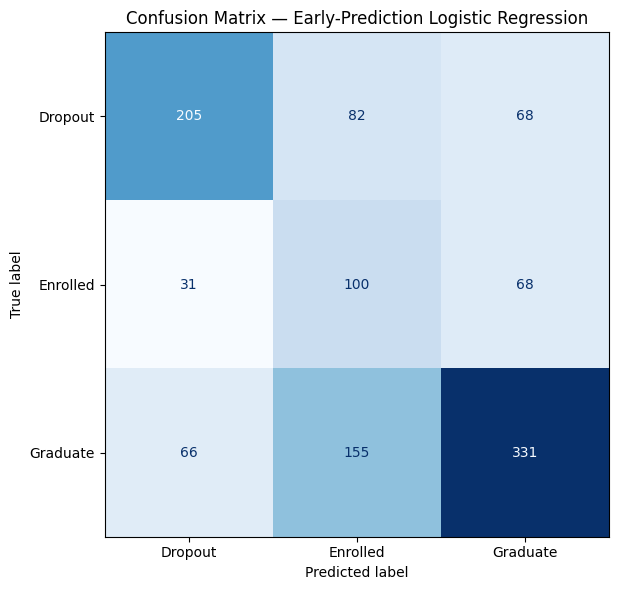

,precision,recall,f1-score,support
Dropout,0.679,0.577,0.624,355.0
Enrolled,0.297,0.503,0.373,199.0
Graduate,0.709,0.600,0.650,552.0
macro avg,0.561,0.560,0.549,1106.0
weighted avg,0.625,0.575,0.592,1106.0


Accuracy: 0.575
Macro precision: 0.5614
Macro recall: 0.5599
Macro F1-score: 0.5489


In [33]:
labels = ["Dropout", "Enrolled", "Graduate"]
cm = confusion_matrix(y_test, y_pred, labels=labels)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Confusion Matrix — Early-Prediction Logistic Regression")
plt.tight_layout()
plt.show()

report_dict = classification_report(y_test, y_pred, labels=labels, output_dict=True, zero_division=0)
report = pd.DataFrame(report_dict).T
display(report.loc[labels + ["macro avg", "weighted avg"], ["precision","recall","f1-score","support"]].round(3))
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro precision:", round(report_dict["macro avg"]["precision"], 4))
print("Macro recall:", round(report_dict["macro avg"]["recall"], 4))
print("Macro F1-score:", round(report_dict["macro avg"]["f1-score"], 4))

# Export metrics and confusion matrix for report/reproducibility.
report.to_csv("classification_report_metrics.csv")
pd.DataFrame(cm, index=labels, columns=labels).to_csv("confusion_matrix.csv")

## 9. Interpret model-derived feature information

Logistic regression coefficients are class-specific and depend on the reference/contrast used by the multinomial model. For each outcome class, large positive or negative coefficients indicate stronger associations with that class's log-odds relative to the model's other classes, conditional on the other encoded predictors. One-hot encoded categories must be interpreted relative to omitted/reference categories and should not be read as causal effects.

In [34]:
fitted_preprocessor = model.named_steps["preprocess"]
fitted_lr = model.named_steps["classifier"]
feature_names = fitted_preprocessor.get_feature_names_out()
coef_df = pd.DataFrame(fitted_lr.coef_, columns=feature_names, index=fitted_lr.classes_)

for cls in fitted_lr.classes_:
    top_positive = coef_df.loc[cls].sort_values(ascending=False).head(8)
    top_negative = coef_df.loc[cls].sort_values().head(8)
    print(f"\n{cls}: largest positive coefficients")
    display(top_positive.to_frame("coefficient").round(3))
    print(f"{cls}: largest negative coefficients")
    display(top_negative.to_frame("coefficient").round(3))

print("Caution: coefficients describe model associations, not causal effects. Correlated predictors, coding choices and regularization affect coefficient sizes.")


Dropout: largest positive coefficients


,coefficient
cat__Mother's occupation_0,1.498
cat__Father's occupation_90,1.047
cat__Mother's occupation_90,1.041
cat__Mother's qualification_9,0.861
cat__Application mode_7,0.819
cat__Father's qualification_10,0.806
cat__Father's qualification_40,0.720
cat__Father's qualification_5,0.666


Dropout: largest negative coefficients


,coefficient
cat__Mother's occupation_191,-1.141
cat__Application mode_15,-1.140
cat__Mother's qualification_4,-0.787
cat__Application mode_53,-0.700
cat__Mother's qualification_2,-0.693
cat__Father's qualification_30,-0.599
cat__Marital status_5,-0.596
cat__Mother's occupation_141,-0.592



Enrolled: largest positive coefficients


...


Graduate: largest positive coefficients


,coefficient
cat__Application mode_15,1.350
cat__Marital status_5,0.868
cat__Nacionality_11,0.778
cat__Father's qualification_43,0.644
cat__Course_9238,0.599
cat__Nacionality_26,0.591
cat__Mother's occupation_171,0.583
cat__Father's qualification_36,0.572


Graduate: largest negative coefficients


,coefficient
cat__Course_9119,-1.187
cat__Father's qualification_39,-0.846
cat__Marital status_6,-0.839
cat__Application mode_39,-0.701
cat__Application mode_7,-0.697
cat__Father's occupation_183,-0.686
cat__Nacionality_108,-0.674
cat__Mother's occupation_122,-0.674


Caution: coefficients describe model associations, not causal effects. Correlated predictors, coding choices and regularization affect coefficient sizes.


## 10. Evidence-based recommendations

1. **Early support, not punishment:** use predictions only to offer voluntary advising, tutoring, financial-aid guidance or wellbeing resources. Do not use them to deny admission, scholarships or course access.
2. **Monitor actual academic signals after enrollment:** first-semester grades and approved-unit counts are strongly relevant to later outcomes in many settings. A separate semester-one model can trigger timely, supportive outreach, provided it is validated prospectively.
3. **Investigate barriers with institutional evidence:** evaluate financial, scheduling and administrative support options. Do not assume a demographic association explains why a student is struggling.
4. **Audit fairness and errors:** compare recall, precision and false-negative rates across relevant student groups, review data quality, and involve student-support staff in decisions.
5. **Evaluate interventions:** track whether outreach improves student outcomes through prospective evaluation rather than assuming the model itself causes improvement.

## 11. Limitations

- The model predicts association with recorded outcomes; it does not establish causation.
- The target is an end-of-normal-duration status, so it may not capture later completion or changes after the observation window.
- The early model intentionally excludes semester performance; its performance may be lower than a model that uses later academic signals.
- Class imbalance can lead to uneven class-level performance even when overall accuracy appears reasonable.
- Logistic regression assumes a linear relationship between encoded features and class log-odds unless feature transformations/interactions are added.
- Dataset codes and historical context may not transfer to another institution or cohort.
- Predictions can reflect structural inequities in historical data; use fairness checks, human review and transparent governance.


